## 0. Setup

In [8]:
!pip install -q imbalanced-learn

In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.dummy import DummyClassifier

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    average_precision_score, roc_auc_score, confusion_matrix,
    precision_recall_curve, ConfusionMatrixDisplay
)

from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE

import joblib
import time
import os

In [10]:

SEED = 42              # same random seed everywhere, so results repeat


In [11]:
BASE = '/content/machine-failure-predictor'

for folder in ['figs', 'models', 'results']:
    os.makedirs(os.path.join(BASE, folder), exist_ok=True)

In [12]:
# Load the dataset
df = pd.read_csv('/content/ai4i2020.csv')

print("Dataset shape:", df.shape)
df.head()

Dataset shape: (10000, 14)


,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


## 1. Load the dataset



In [13]:
import pandas as pd

df = pd.read_csv('/content/ai4i2020.csv')

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

df.head()

Dataset loaded successfully!
Dataset shape: (10000, 14)


,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


In [14]:
print("Last 5 rows:")
display(df.tail())

print("Dataset information:")
df.info()

print("Statistical summary:")
df.describe()

Last 5 rows:


,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
9995,9996,M24855,M,298.8,308.4,1604,29.5,14,0,0,0,0,0,0
9996,9997,H39410,H,298.9,308.4,1632,31.8,17,0,0,0,0,0,0
9997,9998,M24857,M,299.0,308.6,1645,33.4,22,0,0,0,0,0,0
9998,9999,H39412,H,299.0,308.7,1408,48.5,25,0,0,0,0,0,0
9999,10000,M24859,M,299.0,308.7,1500,40.2,30,0,0,0,0,0,0


Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   UDI                      10000 non-null  int64  
 1   Product ID               10000 non-null  object 
 2   Type                     10000 non-null  object 
 3   Air temperature [K]      10000 non-null  float64
 4   Process temperature [K]  10000 non-null  float64
 5   Rotational speed [rpm]   10000 non-null  int64  
 6   Torque [Nm]              10000 non-null  float64
 7   Tool wear [min]          10000 non-null  int64  
 8   Machine failure          10000 non-null  int64  
 9   TWF                      10000 non-null  int64  
 10  HDF                      10000 non-null  int64  
 11  PWF                      10000 non-null  int64  
 12  OSF                      10000 non-null  int64  
 13  RNF                      10000 non-null  int64  
dtypes:

,UDI,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
count,10000.00000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000
mean,5000.50000,300.004930,310.005560,1538.776100,39.986910,107.951000,0.033900,0.004600,0.011500,0.009500,0.009800,0.00190
std,2886.89568,2.000259,1.483734,179.284096,9.968934,63.654147,0.180981,0.067671,0.106625,0.097009,0.098514,0.04355
min,1.00000,295.300000,305.700000,1168.000000,3.800000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
25%,2500.75000,298.300000,308.800000,1423.000000,33.200000,53.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
50%,5000.50000,300.100000,310.100000,1503.000000,40.100000,108.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
75%,7500.25000,301.500000,311.100000,1612.000000,46.800000,162.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
max,10000.00000,304.500000,313.800000,2886.000000,76.600000,253.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.00000


In [15]:
# look at the last rows, the column types and the summary numbers
display(df.tail())
df.info()
display(df.describe().T)

,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
9995,9996,M24855,M,298.8,308.4,1604,29.5,14,0,0,0,0,0,0
9996,9997,H39410,H,298.9,308.4,1632,31.8,17,0,0,0,0,0,0
9997,9998,M24857,M,299.0,308.6,1645,33.4,22,0,0,0,0,0,0
9998,9999,H39412,H,299.0,308.7,1408,48.5,25,0,0,0,0,0,0
9999,10000,M24859,M,299.0,308.7,1500,40.2,30,0,0,0,0,0,0


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   UDI                      10000 non-null  int64  
 1   Product ID               10000 non-null  object 
 2   Type                     10000 non-null  object 
 3   Air temperature [K]      10000 non-null  float64
 4   Process temperature [K]  10000 non-null  float64
 5   Rotational speed [rpm]   10000 non-null  int64  
 6   Torque [Nm]              10000 non-null  float64
 7   Tool wear [min]          10000 non-null  int64  
 8   Machine failure          10000 non-null  int64  
 9   TWF                      10000 non-null  int64  
 10  HDF                      10000 non-null  int64  
 11  PWF                      10000 non-null  int64  
 12  OSF                      10000 non-null  int64  
 13  RNF                      10000 non-null  int64  
dtypes: float64(3), int64(9)

,count,mean,std,min,25%,50%,75%,max
UDI,10000.0,5000.50000,2886.895680,1.0,2500.75,5000.5,7500.25,10000.0
Air temperature [K],10000.0,300.00493,2.000259,295.3,298.30,300.1,301.50,304.5
Process temperature [K],10000.0,310.00556,1.483734,305.7,308.80,310.1,311.10,313.8
Rotational speed [rpm],10000.0,1538.77610,179.284096,1168.0,1423.00,1503.0,1612.00,2886.0
Torque [Nm],10000.0,39.98691,9.968934,3.8,33.20,40.1,46.80,76.6
Tool wear [min],10000.0,107.95100,63.654147,0.0,53.00,108.0,162.00,253.0
Machine failure,10000.0,0.03390,0.180981,0.0,0.00,0.0,0.00,1.0
TWF,10000.0,0.00460,0.067671,0.0,0.00,0.0,0.00,1.0
HDF,10000.0,0.01150,0.106625,0.0,0.00,0.0,0.00,1.0
PWF,10000.0,0.00950,0.097009,0.0,0.00,0.0,0.00,1.0


In [16]:
# give the columns simple names (easier to type)
df = df.rename(columns={
    'UDI': 'udi', 'Product ID': 'product_id', 'Type': 'type',
    'Air temperature [K]': 'air_temp', 'Process temperature [K]': 'process_temp',
    'Rotational speed [rpm]': 'rpm', 'Torque [Nm]': 'torque',
    'Tool wear [min]': 'tool_wear', 'Machine failure': 'failure'})
print(df.columns.tolist())

['udi', 'product_id', 'type', 'air_temp', 'process_temp', 'rpm', 'torque', 'tool_wear', 'failure', 'TWF', 'HDF', 'PWF', 'OSF', 'RNF']


In [17]:
# check missing values and duplicates
print('Missing values per column:')
print(df.isnull().sum())
print('Duplicate rows:', df.duplicated().sum())
print('Duplicate machine ids:', df['product_id'].duplicated().sum())

Missing values per column:
udi             0
product_id      0
type            0
air_temp        0
process_temp    0
rpm             0
torque          0
tool_wear       0
failure         0
TWF             0
HDF             0
PWF             0
OSF             0
RNF             0
dtype: int64
Duplicate rows: 0
Duplicate machine ids: 0


In [18]:
# how many failures are there? this is the class imbalance
print(df['failure'].value_counts())
print((df['failure'].value_counts(normalize=True) * 100).round(2))
print('Failures by type:')
print(df[['TWF', 'HDF', 'PWF', 'OSF', 'RNF']].sum())

failure
0    9661
1     339
Name: count, dtype: int64
failure
0    96.61
1     3.39
Name: proportion, dtype: float64
Failures by type:
TWF     46
HDF    115
PWF     95
OSF     98
RNF     19
dtype: int64


## 2. EDA (exploring the data)



In [19]:
# Check the first 5 rows
df.head()

,udi,product_id,type,air_temp,process_temp,rpm,torque,tool_wear,failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


In [20]:
# Check the last 5 rows
df.tail()

,udi,product_id,type,air_temp,process_temp,rpm,torque,tool_wear,failure,TWF,HDF,PWF,OSF,RNF
9995,9996,M24855,M,298.8,308.4,1604,29.5,14,0,0,0,0,0,0
9996,9997,H39410,H,298.9,308.4,1632,31.8,17,0,0,0,0,0,0
9997,9998,M24857,M,299.0,308.6,1645,33.4,22,0,0,0,0,0,0
9998,9999,H39412,H,299.0,308.7,1408,48.5,25,0,0,0,0,0,0
9999,10000,M24859,M,299.0,308.7,1500,40.2,30,0,0,0,0,0,0


In [21]:
# Check the number of rows and columns
print("Dataset shape:", df.shape)

# Check column names
print(df.columns)

# Check data types and non-null values
df.info()

Dataset shape: (10000, 14)
Index(['udi', 'product_id', 'type', 'air_temp', 'process_temp', 'rpm',
       'torque', 'tool_wear', 'failure', 'TWF', 'HDF', 'PWF', 'OSF', 'RNF'],
      dtype='object')
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   udi           10000 non-null  int64  
 1   product_id    10000 non-null  object 
 2   type          10000 non-null  object 
 3   air_temp      10000 non-null  float64
 4   process_temp  10000 non-null  float64
 5   rpm           10000 non-null  int64  
 6   torque        10000 non-null  float64
 7   tool_wear     10000 non-null  int64  
 8   failure       10000 non-null  int64  
 9   TWF           10000 non-null  int64  
 10  HDF           10000 non-null  int64  
 11  PWF           10000 non-null  int64  
 12  OSF           10000 non-null  int64  
 13  RNF           10000 non-null  int64  
dtypes:

In [22]:
# Check missing values in each column
print(df.isnull().sum())

# Check duplicate rows
print("Duplicate rows:", df.duplicated().sum())

udi             0
product_id      0
type            0
air_temp        0
process_temp    0
rpm             0
torque          0
tool_wear       0
failure         0
TWF             0
HDF             0
PWF             0
OSF             0
RNF             0
dtype: int64
Duplicate rows: 0


failure
0    9661
1     339
Name: count, dtype: int64


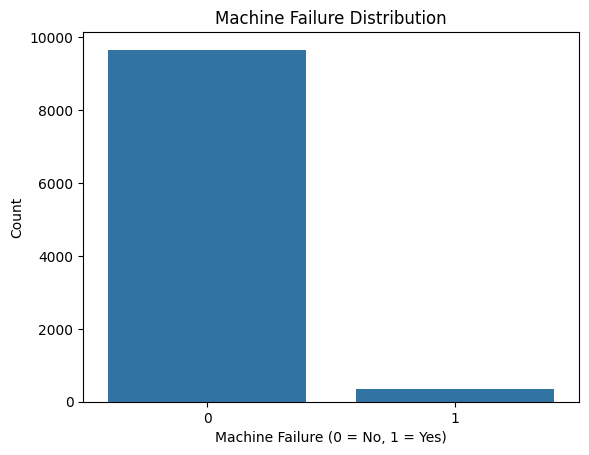

In [23]:
# Count the number of failures and non-failures
print(df['failure'].value_counts())

# Plot the failure distribution
sns.countplot(data=df, x='failure')
plt.title('Machine Failure Distribution')
plt.xlabel('Machine Failure (0 = No, 1 = Yes)')
plt.ylabel('Count')
plt.show()

In [24]:
# small helper that saves every figure in the figs folder
def save_fig(name):
    plt.tight_layout()
    plt.savefig(os.path.join(BASE, 'figs', name + '.png'), dpi=150, bbox_inches='tight')
    plt.show()

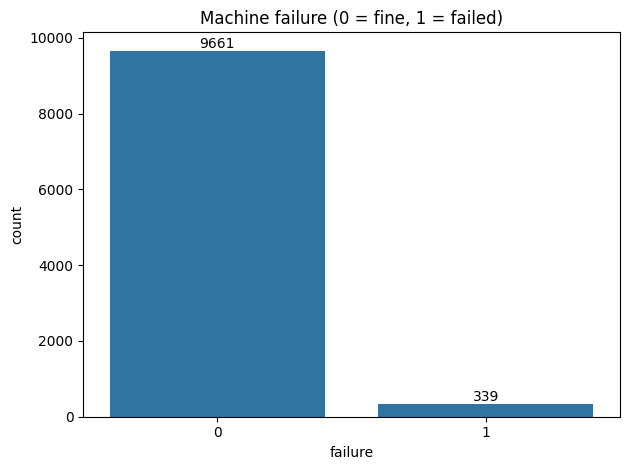

In [25]:
# figure 1: failure vs no failure
ax = sns.countplot(x='failure', data=df)
ax.bar_label(ax.containers[0])
plt.title('Machine failure (0 = fine, 1 = failed)')
save_fig('01_failure_count')

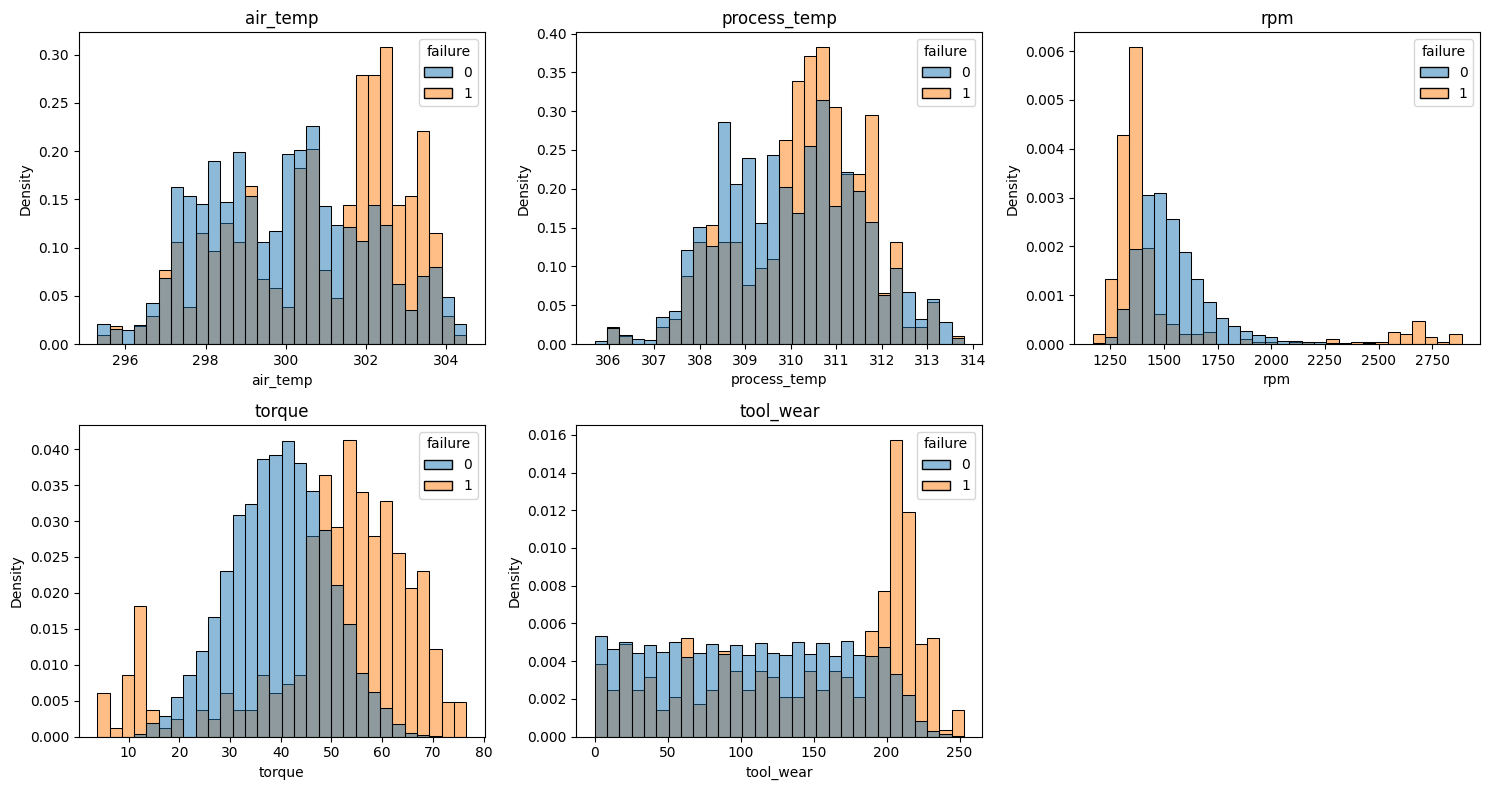

In [26]:
# figure 2: how each reading looks for fine machines and failed machines
readings = ['air_temp', 'process_temp', 'rpm', 'torque', 'tool_wear']
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.flat, readings):
    sns.histplot(data=df, x=col, hue='failure', stat='density', common_norm=False, bins=30, ax=ax)
    ax.set_title(col)
axes.flat[-1].axis('off')
save_fig('02_histograms')

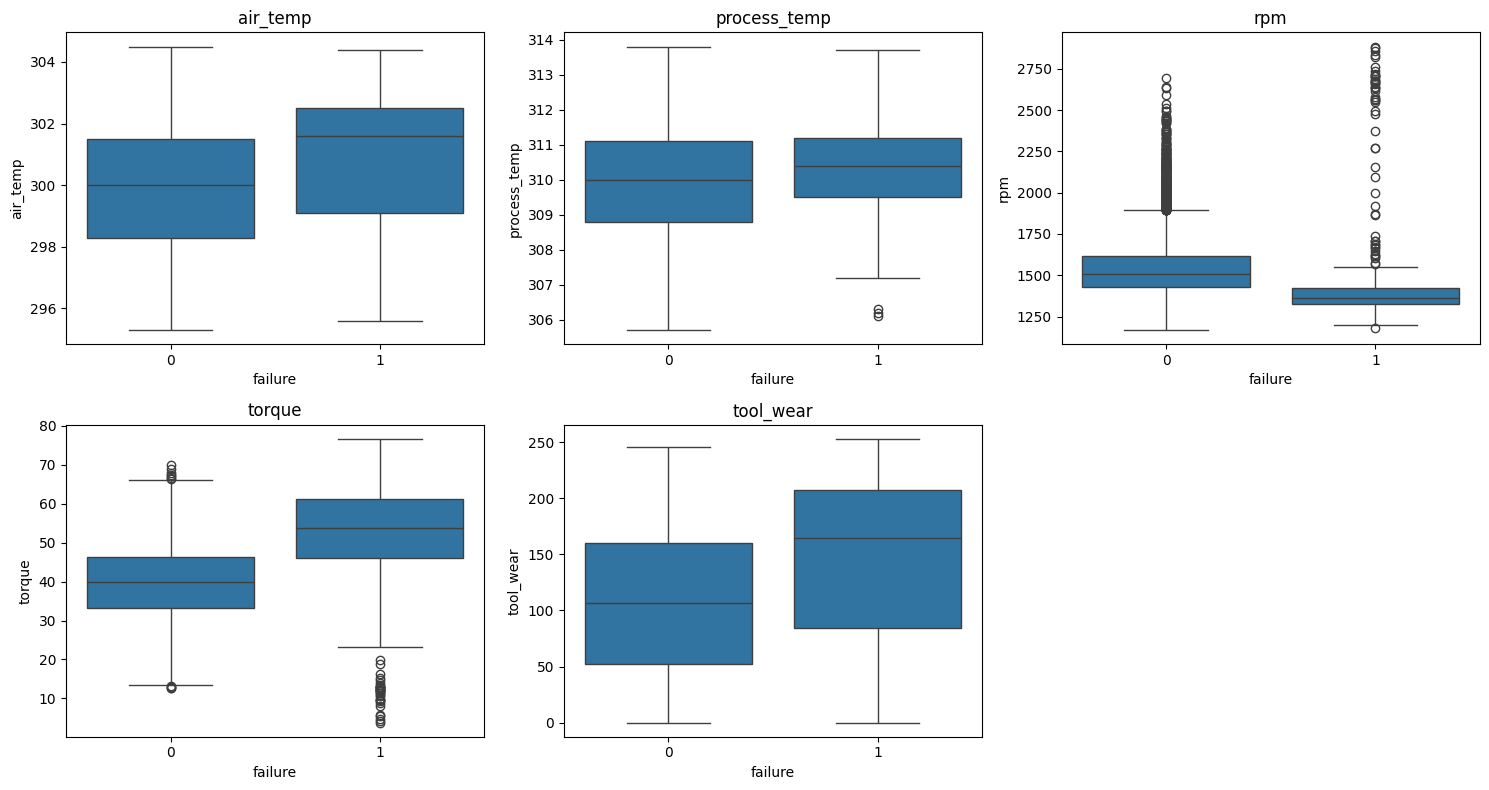

In [27]:
# figure 3: box plots (the dots are outliers, we keep them because failures live there)
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.flat, readings):
    sns.boxplot(data=df, x='failure', y=col, ax=ax)
    ax.set_title(col)
axes.flat[-1].axis('off')
save_fig('03_boxplots')

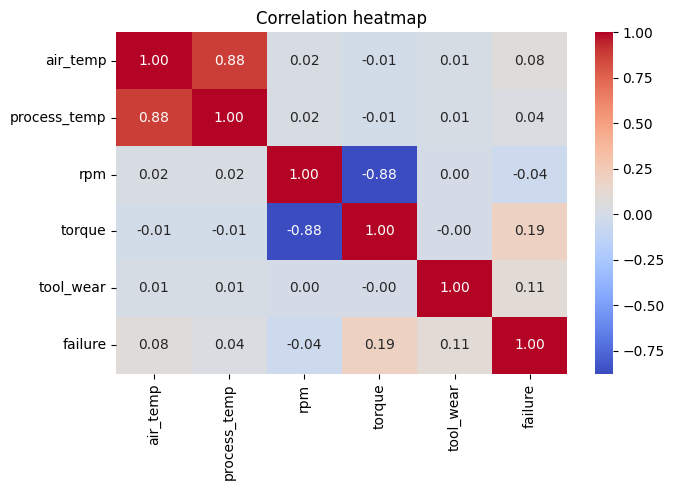

In [28]:
# figure 4: correlation heatmap
plt.figure(figsize=(7, 5))
sns.heatmap(df[readings + ['failure']].corr(), annot=True, fmt='.2f', cmap='coolwarm')
plt.title('Correlation heatmap')
save_fig('04_correlation')

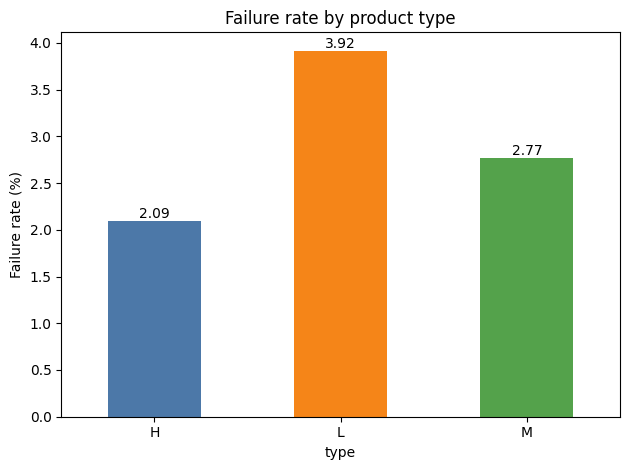

In [29]:
# figure 5: failure rate for each product type (L, M, H)
rate = df.groupby('type')['failure'].mean() * 100
ax = rate.plot(kind='bar', color=['#4c78a8', '#f58518', '#54a24b'], rot=0)
ax.bar_label(ax.containers[0], fmt='%.2f')
plt.ylabel('Failure rate (%)')
plt.title('Failure rate by product type')
save_fig('05_failure_by_type')

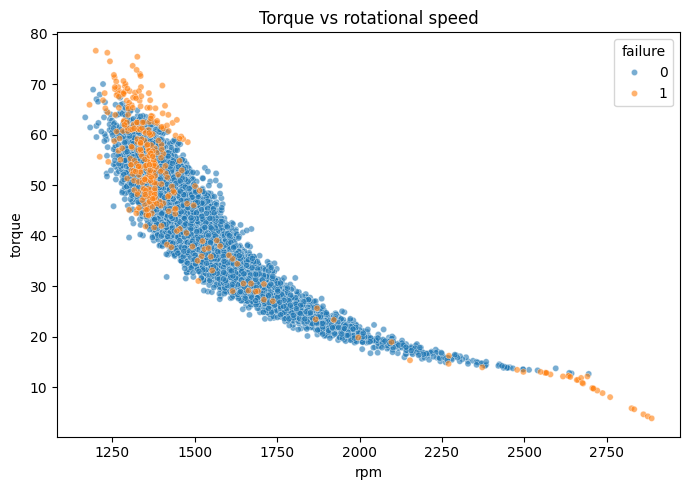

In [30]:
# figure 6: torque vs speed, coloured by failure (failures drawn last so they stay visible)
plt.figure(figsize=(7, 5))
sns.scatterplot(data=df.sort_values('failure'), x='rpm', y='torque', hue='failure', alpha=0.6, s=20)
plt.title('Torque vs rotational speed')
save_fig('06_torque_rpm')

## 3. Cleaning and new features



In [31]:
# cleaning step 1: drop the id columns and the 5 failure-type columns (they leak the answer)
LEAK = ['TWF', 'HDF', 'PWF', 'OSF', 'RNF']
IDS = ['udi', 'product_id']
clean = df.drop(columns=IDS + LEAK)
print('Columns kept:', clean.columns.tolist())

Columns kept: ['type', 'air_temp', 'process_temp', 'rpm', 'torque', 'tool_wear', 'failure']


In [32]:
# cleaning step 2: build the new features and encode the type column
BASE_COLS = ['air_temp', 'process_temp', 'rpm', 'torque', 'tool_wear']
FEATURES = BASE_COLS + ['temp_diff', 'power', 'wear_torque', 'type_L', 'type_M']

def make_features(d):
    out = d[BASE_COLS].copy()
    out['temp_diff'] = d['process_temp'] - d['air_temp']
    out['power'] = d['torque'] * d['rpm'] * 2 * np.pi / 60
    out['wear_torque'] = d['tool_wear'] * d['torque']
    out['type_L'] = (d['type'] == 'L').astype(int)
    out['type_M'] = (d['type'] == 'M').astype(int)
    return out[FEATURES]

X = make_features(clean)
y = clean['failure']
print('Features:', X.shape, ' Target:', y.shape)
X.head()

Features: (10000, 10)  Target: (10000,)


,air_temp,process_temp,rpm,torque,tool_wear,temp_diff,power,wear_torque,type_L,type_M
0,298.1,308.6,1551,42.8,0,10.5,6951.590560,0.0,0,1
1,298.2,308.7,1408,46.3,3,10.5,6826.722724,138.9,1,0
2,298.1,308.5,1498,49.4,5,10.4,7749.387543,247.0,1,0
3,298.2,308.6,1433,39.5,7,10.4,5927.504659,276.5,1,0
4,298.2,308.7,1408,40.0,9,10.5,5897.816608,360.0,1,0


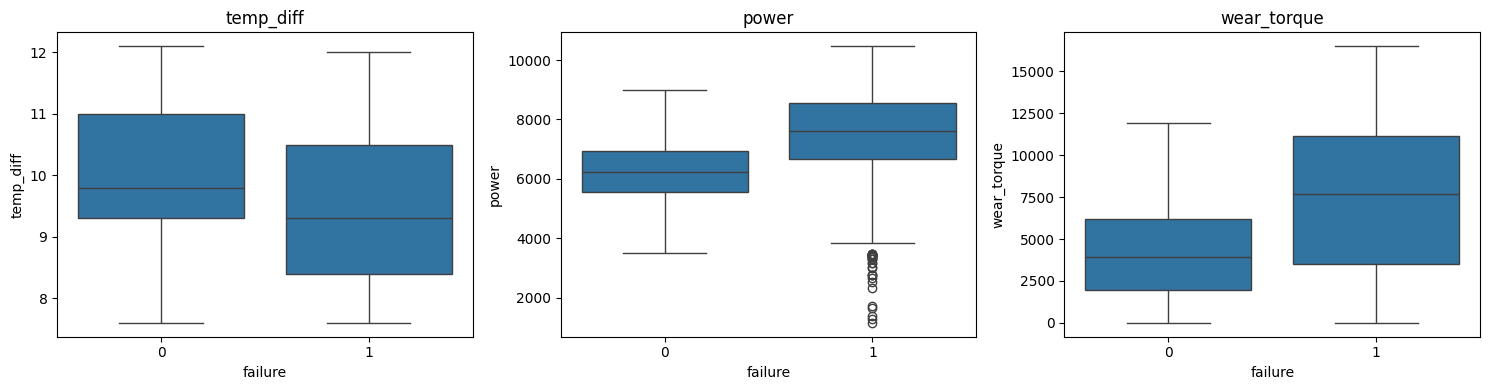

In [33]:
# figure 7: the new features for fine and failed machines
new_cols = ['temp_diff', 'power', 'wear_torque']
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, new_cols):
    sns.boxplot(x=y, y=X[col], ax=ax)
    ax.set_title(col)
save_fig('07_new_features')

## 4. Train and test split (no leakage)



In [34]:
# split 80% train and 20% test, stratified
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)
print('Train:', X_train.shape, ' Test:', X_test.shape)
print('Failure rate in train: %.2f %%' % (y_train.mean() * 100))
print('Failure rate in test : %.2f %%' % (y_test.mean() * 100))

Train: (8000, 10)  Test: (2000, 10)
Failure rate in train: 3.39 %
Failure rate in test : 3.40 %


In [35]:
# leakage proof: a tree that is allowed to see the failure-type columns looks perfect (this is fake)
train_leaky = X_train.join(df.loc[X_train.index, LEAK])
test_leaky = X_test.join(df.loc[X_test.index, LEAK])
leak_model = DecisionTreeClassifier(max_depth=5, random_state=SEED).fit(train_leaky, y_train)
honest_model = DecisionTreeClassifier(max_depth=5, random_state=SEED).fit(X_train, y_train)
print('F1 WITH the leak columns   : %.3f  (fake, too good to be true)' % f1_score(y_test, leak_model.predict(test_leaky)))
print('F1 WITHOUT the leak columns: %.3f  (honest)' % f1_score(y_test, honest_model.predict(X_test)))

F1 WITH the leak columns   : 0.985  (fake, too good to be true)
F1 WITHOUT the leak columns: 0.882  (honest)


In [36]:
# baseline: a "model" that always says no failure (shows why accuracy is not enough)
dummy = DummyClassifier(strategy='most_frequent').fit(X_train, y_train)
print('Dummy accuracy: %.3f' % accuracy_score(y_test, dummy.predict(X_test)))
print('Dummy F1 for failures: %.3f' % f1_score(y_test, dummy.predict(X_test), zero_division=0))

Dummy accuracy: 0.966
Dummy F1 for failures: 0.000


## 5. Models, imbalance handling and tuning




In [37]:
# metrics function: precision, recall, F1, PR-AUC, ROC-AUC, accuracy and the confusion matrix numbers
def evaluate(model, X_data, y_data, threshold=0.5):
    proba = model.predict_proba(X_data)[:, 1]
    pred = (proba >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_data, pred, labels=[0, 1]).ravel()
    return {
        'precision': precision_score(y_data, pred, zero_division=0),
        'recall': recall_score(y_data, pred, zero_division=0),
        'f1': f1_score(y_data, pred, zero_division=0),
        'pr_auc': average_precision_score(y_data, proba),
        'roc_auc': roc_auc_score(y_data, proba),
        'accuracy': accuracy_score(y_data, pred),
        'TP': int(tp), 'FP': int(fp), 'FN': int(fn), 'TN': int(tn)}

In [38]:
# build one model and one pipeline (scaler -> optional SMOTE -> model)
def get_model(name, imbalance):
    cw = 'balanced' if imbalance == 'class_weight' else None
    if name == 'Logistic Regression':
        return LogisticRegression(max_iter=1000, class_weight=cw)
    if name == 'KNN':
        return KNeighborsClassifier()
    if name == 'Decision Tree':
        return DecisionTreeClassifier(class_weight=cw, random_state=SEED)
    if name == 'Random Forest':
        return RandomForestClassifier(class_weight=cw, random_state=SEED, n_jobs=1)
    if name == 'LDA':
        return LinearDiscriminantAnalysis()
    if name == 'AdaBoost':
        return AdaBoostClassifier(random_state=SEED)

def make_pipeline(name, imbalance):
    steps = [('scaler', StandardScaler())]
    if imbalance == 'smote':
        steps.append(('smote', SMOTE(random_state=SEED)))
    steps.append(('model', get_model(name, imbalance)))
    # Use ImbPipeline instead of the standard sklearn Pipeline
    return ImbPipeline(steps)

# which imbalance options each model can use
OPTIONS = {
    'Logistic Regression': ['none', 'class_weight', 'smote'],
    'KNN': ['none', 'smote'],
    'Decision Tree': ['none', 'class_weight', 'smote'],
    'Random Forest': ['none', 'class_weight', 'smote'],
    'LDA': ['none', 'smote'],
    'AdaBoost': ['none', 'smote']}

In [39]:
# Define QUICK (True for fast run, False for complete search)
QUICK = True

if QUICK:
    GRIDS = {
        'Logistic Regression': {'model__C': [0.1, 1]},
        'KNN': {'model__n_neighbors': [5, 9]},
        'Decision Tree': {'model__max_depth': [5, 10]},
        'Random Forest': {'model__n_estimators': [30], 'model__max_depth': [5, None]},
        'LDA': {'model__solver': ['svd']},
        'AdaBoost': {'model__n_estimators': [30], 'model__learning_rate': [0.5, 1.0]}}
else:
    GRIDS = {
        'Logistic Regression': {'model__C': [0.01, 0.1, 1, 10, 100]},
        'KNN': {'model__n_neighbors': [3, 5, 7, 9, 11, 15],
                'model__weights': ['uniform', 'distance'],
                'model__metric': ['euclidean', 'manhattan']},
        'Decision Tree': {'model__max_depth': [3, 5, 7, 10, None],
                          'model__min_samples_leaf': [1, 5, 10],
                          'model__criterion': ['gini', 'entropy']},
        'Random Forest': {'model__n_estimators': [100, 200, 300],
                          'model__max_depth': [5, 10, None],
                          'model__min_samples_leaf': [1, 5]},
        'LDA': [{'model__solver': ['svd']},
                {'model__solver': ['lsqr'], 'model__shrinkage': [None, 'auto', 0.1, 0.5]}],
        'AdaBoost': {'model__n_estimators': [50, 100, 200],
                     'model__learning_rate': [0.1, 0.5, 1.0]}}

In [40]:
from sklearn.model_selection import cross_val_score

# Define the number of cross-validation folds
CV_FOLDS = 5

cv = StratifiedKFold(n_splits=CV_FOLDS, shuffle=True, random_state=SEED)
before_f1 = {}
for name in OPTIONS:
    scores = cross_val_score(make_pipeline(name, 'none'), X_train, y_train, cv=cv, scoring='f1', n_jobs=-1)
    before_f1[name] = scores.mean()
    print('%-20s F1 before tuning: %.3f' % (name, before_f1[name]))

Logistic Regression  F1 before tuning: 0.374
KNN                  F1 before tuning: 0.460
Decision Tree        F1 before tuning: 0.824
Random Forest        F1 before tuning: 0.893
LDA                  F1 before tuning: 0.406
AdaBoost             F1 before tuning: 0.571


In [41]:
import json

# train and tune every model with GridSearchCV (each finished model is saved to Drive, so a restart can skip it)
TUNE_DIR = os.path.join(BASE, 'models', 'tuned')
os.makedirs(TUNE_DIR, exist_ok=True)
JSON_PATH = os.path.join(BASE, 'results', 'tuning_results.json')
saved = json.load(open(JSON_PATH)) if os.path.exists(JSON_PATH) else {}

estimators = {}
rows = []
for name in OPTIONS:
    for imb in OPTIONS[name]:
        key = name + ' | ' + imb
        path = os.path.join(TUNE_DIR, (name + '_' + imb).replace(' ', '_') + '.joblib')
        if key in saved and os.path.exists(path):
            best = joblib.load(path)
            cv_f1 = saved[key]['cv_f1']
            params = saved[key]['params']
            print('loaded from disk:', key)
        else:
            start = time.time()
            grid = GridSearchCV(make_pipeline(name, imb), GRIDS[name], scoring='f1', cv=cv, n_jobs=-1)
            grid.fit(X_train, y_train)
            best, cv_f1, params = grid.best_estimator_, float(grid.best_score_), grid.best_params_
            joblib.dump(best, path)
            saved[key] = {'cv_f1': cv_f1, 'params': {k: str(v) for k, v in params.items()}}
            json.dump(saved, open(JSON_PATH, 'w'), indent=2)
            params = saved[key]['params']
            print('%-32s cv F1 = %.3f  (%.0f s)' % (key, cv_f1, time.time() - start))
        estimators[key] = best
        row = {'model': name, 'imbalance': imb, 'cv_f1': cv_f1, 'best_params': str(params)}
        row.update(evaluate(best, X_test, y_test))
        rows.append(row)

results = pd.DataFrame(rows)
results.to_csv(os.path.join(BASE, 'results', 'all_results.csv'), index=False)
print('Done. Saved results/all_results.csv')

Logistic Regression | none       cv F1 = 0.374  (0 s)
Logistic Regression | class_weight cv F1 = 0.271  (0 s)
Logistic Regression | smote      cv F1 = 0.274  (0 s)
KNN | none                       cv F1 = 0.460  (0 s)
KNN | smote                      cv F1 = 0.453  (1 s)
Decision Tree | none             cv F1 = 0.888  (0 s)
Decision Tree | class_weight     cv F1 = 0.633  (0 s)
Decision Tree | smote            cv F1 = 0.574  (1 s)
Random Forest | none             cv F1 = 0.890  (2 s)
Random Forest | class_weight     cv F1 = 0.842  (2 s)
Random Forest | smote            cv F1 = 0.737  (4 s)
LDA | none                       cv F1 = 0.406  (0 s)
LDA | smote                      cv F1 = 0.285  (0 s)
AdaBoost | none                  cv F1 = 0.475  (2 s)
AdaBoost | smote                 cv F1 = 0.430  (4 s)
Done. Saved results/all_results.csv


## 6. Compare the models



In [42]:
# imbalance comparison: cross-validation F1 for every model and every imbalance option
pivot = results.pivot(index='model', columns='imbalance', values='cv_f1').round(3)
display(pivot)
pivot.to_csv(os.path.join(BASE, 'results', 'imbalance_comparison.csv'))

imbalance,class_weight,none,smote
model,,,
AdaBoost,NaN,0.475,0.430
Decision Tree,0.633,0.888,0.574
KNN,NaN,0.460,0.453
LDA,NaN,0.406,0.285
Logistic Regression,0.271,0.374,0.274
Random Forest,0.842,0.890,0.737


In [43]:
from sklearn import clone

# pick the best option of each model, record training time, and save the final comparison table
best_rows = results.loc[results.groupby('model')['cv_f1'].idxmax()].copy()
fit_seconds = []
for _, r in best_rows.iterrows():
    start = time.time()
    clone(estimators[r['model'] + ' | ' + r['imbalance']]).fit(X_train, y_train)
    fit_seconds.append(round(time.time() - start, 2))
best_rows['fit_seconds'] = fit_seconds
best_rows['cv_f1_before_tuning'] = best_rows['model'].map(before_f1)
best_rows = best_rows.sort_values('cv_f1', ascending=False).reset_index(drop=True)

show_cols = ['model', 'imbalance', 'cv_f1_before_tuning', 'cv_f1', 'precision', 'recall', 'f1', 'pr_auc', 'roc_auc', 'accuracy', 'fit_seconds']
best_rows[show_cols].to_csv(os.path.join(BASE, 'results', 'best_per_model.csv'), index=False)
display(best_rows[show_cols].round(3))

,model,imbalance,cv_f1_before_tuning,cv_f1,precision,recall,f1,pr_auc,roc_auc,accuracy,fit_seconds
0,Random Forest,none,0.893,0.890,0.965,0.809,0.880,0.880,0.976,0.992,0.38
1,Decision Tree,none,0.824,0.888,0.949,0.824,0.882,0.841,0.942,0.992,0.03
2,AdaBoost,none,0.571,0.475,0.846,0.324,0.468,0.722,0.960,0.975,0.25
3,KNN,none,0.460,0.460,0.870,0.294,0.440,0.502,0.867,0.974,0.01
4,LDA,none,0.406,0.406,0.510,0.382,0.437,0.447,0.904,0.966,0.01
5,Logistic Regression,none,0.374,0.374,0.571,0.176,0.270,0.462,0.925,0.968,0.02


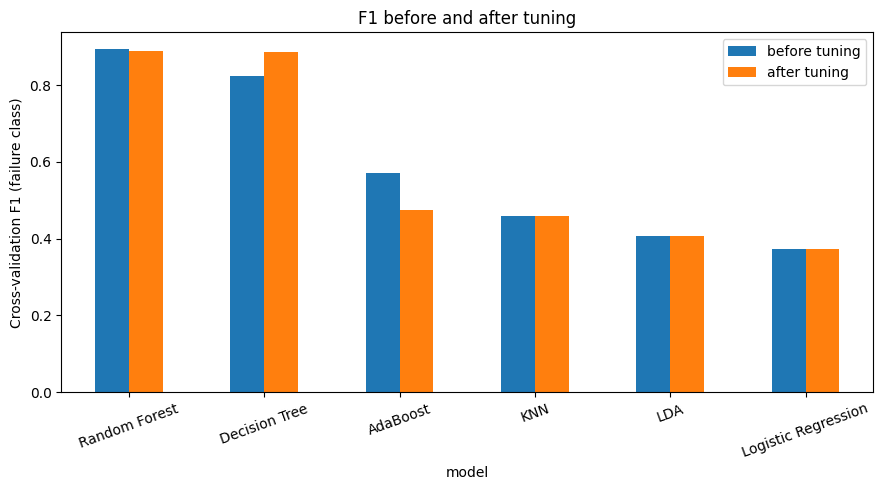

In [44]:
# figure 8: F1 before and after tuning (cross-validation on the training set)
plot_df = best_rows[['model', 'cv_f1_before_tuning', 'cv_f1']].set_index('model')
plot_df.columns = ['before tuning', 'after tuning']
ax = plot_df.plot(kind='bar', figsize=(9, 5), rot=20)
plt.ylabel('Cross-validation F1 (failure class)')
plt.title('F1 before and after tuning')
save_fig('08_before_after_tuning')

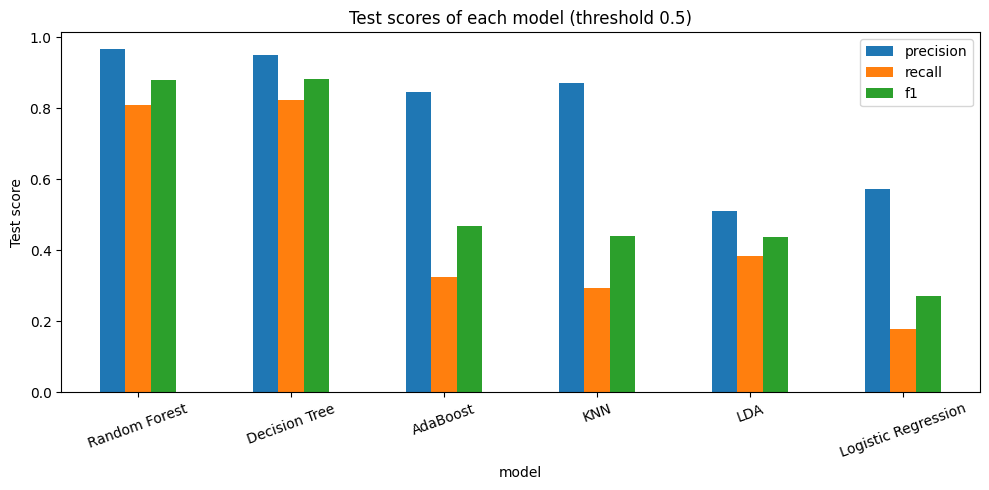

In [45]:
# figure 9: precision, recall and F1 on the test set for the best setting of each model
ax = best_rows.set_index('model')[['precision', 'recall', 'f1']].plot(kind='bar', figsize=(10, 5), rot=20)
plt.ylabel('Test score')
plt.title('Test scores of each model (threshold 0.5)')
save_fig('09_test_scores')

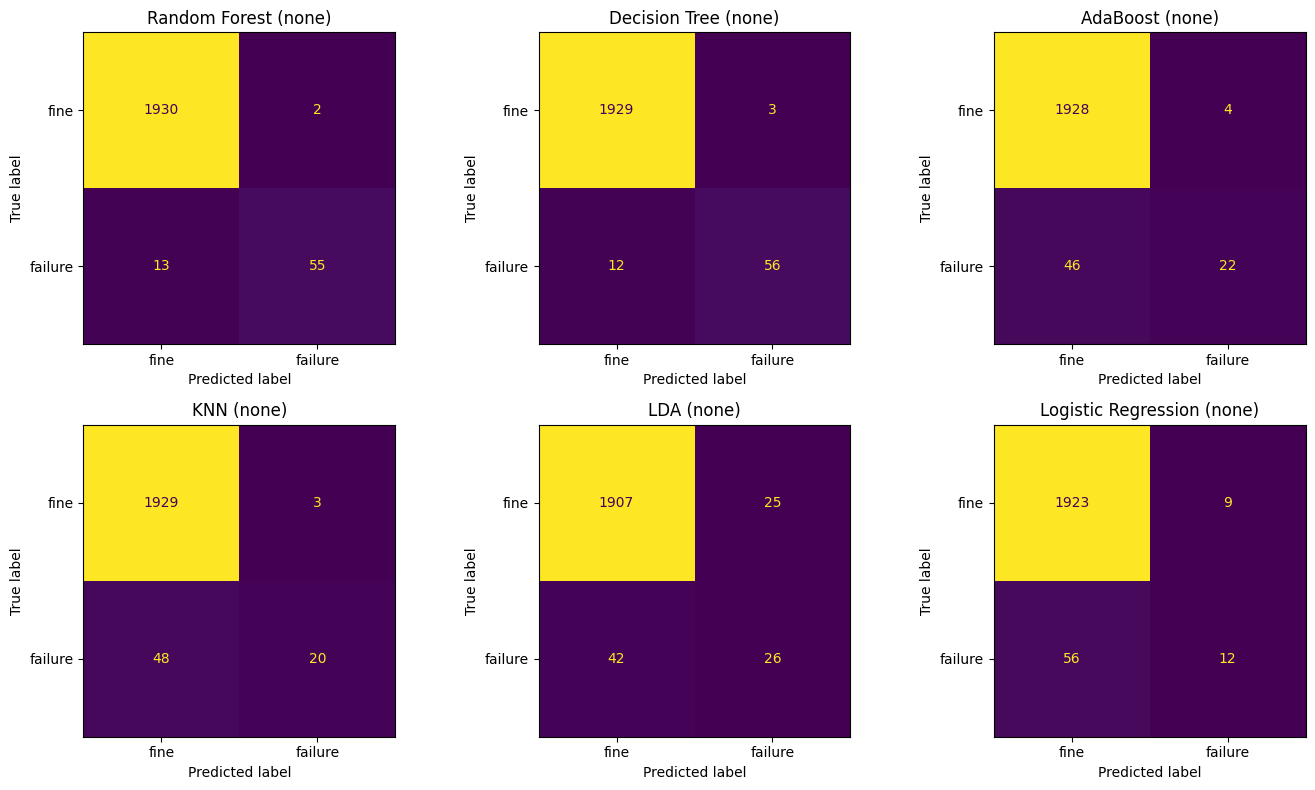

In [46]:
# figure 10: confusion matrices of all six models (threshold 0.5)
fig, axes = plt.subplots(2, 3, figsize=(14, 8))
for ax, (_, r) in zip(axes.flat, best_rows.iterrows()):
    est = estimators[r['model'] + ' | ' + r['imbalance']]
    pred = (est.predict_proba(X_test)[:, 1] >= 0.5).astype(int)
    ConfusionMatrixDisplay(confusion_matrix(y_test, pred), display_labels=['fine', 'failure']).plot(ax=ax, colorbar=False)
    ax.set_title(r['model'] + ' (' + r['imbalance'] + ')')
save_fig('10_confusion_matrices')

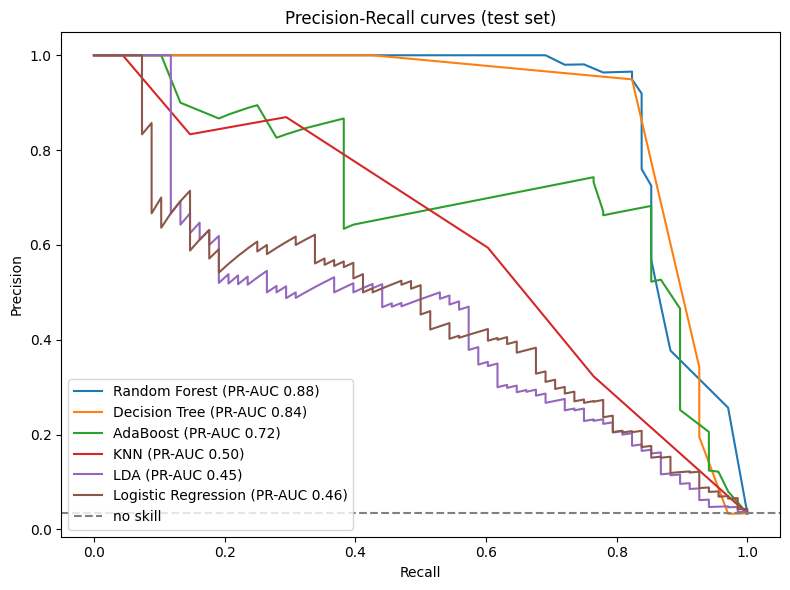

In [47]:
# figure 11: precision-recall curves of all six models on the test set
plt.figure(figsize=(8, 6))
for _, r in best_rows.iterrows():
    est = estimators[r['model'] + ' | ' + r['imbalance']]
    p, rc, _ = precision_recall_curve(y_test, est.predict_proba(X_test)[:, 1])
    plt.plot(rc, p, label='%s (PR-AUC %.2f)' % (r['model'], r['pr_auc']))
plt.axhline(y_test.mean(), color='grey', linestyle='--', label='no skill')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall curves (test set)')
plt.legend()
save_fig('11_pr_curves')

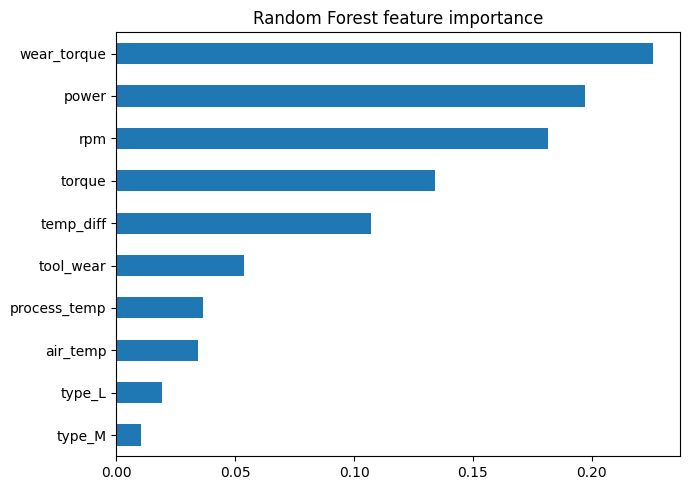

wear_torque     0.226
power           0.197
rpm             0.182
torque          0.134
temp_diff       0.107
tool_wear       0.054
process_temp    0.037
air_temp        0.034
type_L          0.019
type_M          0.010
dtype: float64


In [48]:
# figure 12: which features does the Random Forest use most?
rf_key = best_rows.loc[best_rows['model'] == 'Random Forest', ['model', 'imbalance']].iloc[0]
rf_model = estimators[rf_key['model'] + ' | ' + rf_key['imbalance']].named_steps['model']
importance = pd.Series(rf_model.feature_importances_, index=FEATURES).sort_values()
importance.plot(kind='barh', figsize=(7, 5))
plt.title('Random Forest feature importance')
save_fig('12_feature_importance')
print(importance.sort_values(ascending=False).round(3))

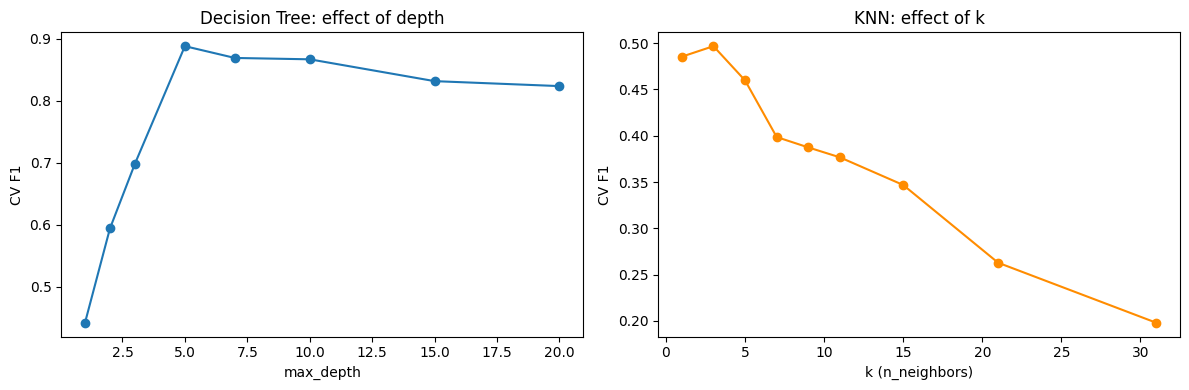

In [49]:
# figure 13: effect of one setting each - tree depth for the Decision Tree and k for KNN (cross-validation on train)
depths = [1, 2, 3, 5, 7, 10, 15, 20]
ks = [1, 3, 5, 7, 9, 11, 15, 21, 31]
tree_scores = []
for d in depths:
    pipe_d = Pipeline([('scaler', StandardScaler()), ('model', DecisionTreeClassifier(max_depth=d, random_state=SEED))])
    tree_scores.append(cross_val_score(pipe_d, X_train, y_train, cv=cv, scoring='f1', n_jobs=-1).mean())
knn_scores = []
for k in ks:
    pipe_k = Pipeline([('scaler', StandardScaler()), ('model', KNeighborsClassifier(n_neighbors=k))])
    knn_scores.append(cross_val_score(pipe_k, X_train, y_train, cv=cv, scoring='f1', n_jobs=-1).mean())

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(depths, tree_scores, marker='o')
axes[0].set_xlabel('max_depth')
axes[0].set_ylabel('CV F1')
axes[0].set_title('Decision Tree: effect of depth')
axes[1].plot(ks, knn_scores, marker='o', color='darkorange')
axes[1].set_xlabel('k (n_neighbors)')
axes[1].set_ylabel('CV F1')
axes[1].set_title('KNN: effect of k')
save_fig('13_setting_curves')

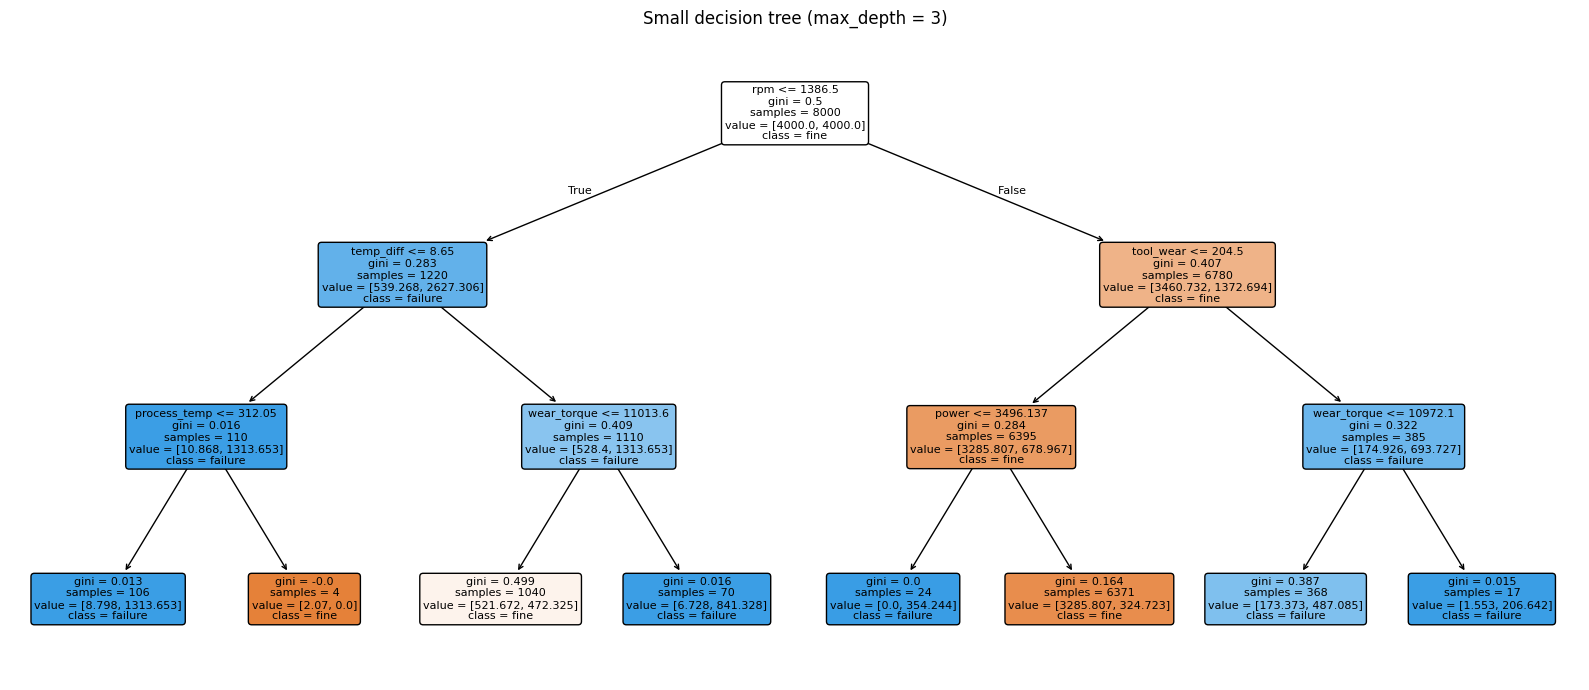

In [50]:
from sklearn.tree import plot_tree

# figure 15: a small decision tree (depth 3) that is easy to read in the report
small_tree = DecisionTreeClassifier(max_depth=3, class_weight='balanced', random_state=SEED).fit(X_train, y_train)
plt.figure(figsize=(16, 7))
plot_tree(small_tree, feature_names=FEATURES, class_names=['fine', 'failure'], filled=True, rounded=True, fontsize=8)
plt.title('Small decision tree (max_depth = 3)')
save_fig('15_decision_tree')

## 7. Final model and alert threshold



In [51]:
# pick the final model (highest cross-validation F1)
final_row = results.loc[results['cv_f1'].idxmax()]
final_key = final_row['model'] + ' | ' + final_row['imbalance']
final_model = estimators[final_key]
print('Final model:', final_key)
print('Best settings:', final_row['best_params'])

Final model: Random Forest | none
Best settings: {'model__max_depth': 'None', 'model__n_estimators': '30'}


Chosen alert threshold: 0.533


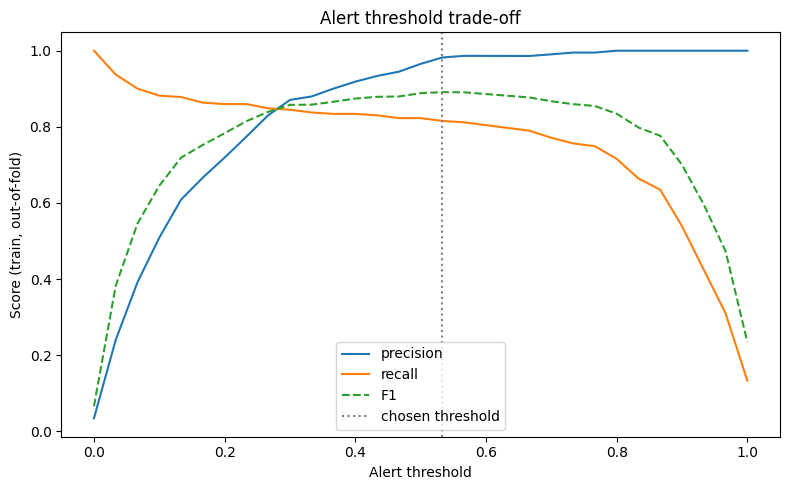

In [52]:
from sklearn.model_selection import cross_val_predict
from sklearn.base import clone

# choose the alert threshold from out-of-fold predictions on the TRAIN set (best F1)
oof = cross_val_predict(clone(final_model), X_train, y_train, cv=cv, method='predict_proba', n_jobs=-1)[:, 1]
prec, rec, thr_list = precision_recall_curve(y_train, oof)
f1_curve = np.divide(2 * prec * rec, prec + rec, out=np.zeros_like(prec), where=(prec + rec) > 0)
best_i = int(np.argmax(f1_curve[:-1]))
THRESHOLD = float(thr_list[best_i])
print('Chosen alert threshold: %.3f' % THRESHOLD)

# figure 14: precision and recall as the threshold moves
plt.figure(figsize=(8, 5))
plt.plot(thr_list, prec[:-1], label='precision')
plt.plot(thr_list, rec[:-1], label='recall')
plt.plot(thr_list, f1_curve[:-1], label='F1', linestyle='--')
plt.axvline(THRESHOLD, color='grey', linestyle=':', label='chosen threshold')
plt.xlabel('Alert threshold')
plt.ylabel('Score (train, out-of-fold)')
plt.title('Alert threshold trade-off')
plt.legend()
save_fig('14_threshold')

In [53]:
# the final test result: the test set is used here for the final score
final_scores = evaluate(final_model, X_test, y_test, threshold=THRESHOLD)
for k, v in final_scores.items():
    print('%-10s %s' % (k, round(v, 3) if isinstance(v, float) else v))
print()
print('Confusion matrix on the test set (rows = real, columns = predicted):')
print(pd.DataFrame([[final_scores['TN'], final_scores['FP']], [final_scores['FN'], final_scores['TP']]],
                   index=['real fine', 'real failure'], columns=['pred fine', 'pred failure']))

precision  0.964
recall     0.794
f1         0.871
pr_auc     0.88
roc_auc    0.976
accuracy   0.992
TP         54
FP         2
FN         14
TN         1930

Confusion matrix on the test set (rows = real, columns = predicted):
              pred fine  pred failure
real fine          1930             2
real failure         14            54


## 8. Save the model for the app

The file `models/best_model.joblib` holds the whole pipeline (scaler, SMOTE if used, model) plus the slider ranges, the alert threshold and a few ready-made example machines for the demo.

In [54]:
# ready-made examples for the app (typical readings of real fine and failed machines from the data)
def typical(mask):
    part = df[mask]
    if len(part) == 0:
        return None
    ex = {c: float(part[c].median()) for c in BASE_COLS}
    ex['type'] = part['type'].mode().iloc[0]
    return ex

presets = {
    'Healthy machine': typical(df['failure'] == 0),
    'Overheating': typical(df['HDF'] == 1),
    'Power problem': typical(df['PWF'] == 1),
    'Overstrain': typical(df['OSF'] == 1),
    'Worn tool': typical(df['TWF'] == 1)}
presets = {k: v for k, v in presets.items() if v is not None}
print(list(presets))

['Healthy machine', 'Overheating', 'Power problem', 'Overstrain', 'Worn tool']


In [55]:
import sklearn

# save the model bundle
bundle = {
    'pipeline': final_model,
    'features': FEATURES,
    'base_cols': BASE_COLS,
    'threshold': THRESHOLD,
    'model_name': final_row['model'],
    'imbalance': final_row['imbalance'],
    'ranges': {c: [float(X_train[c].min()), float(X_train[c].max())] for c in BASE_COLS},
    'presets': presets,
    'test_metrics': final_scores,
    'sklearn_version': sklearn.__version__}
joblib.dump(bundle, os.path.join(BASE, 'models', 'best_model.joblib'))
print('Saved models/best_model.joblib  (scikit-learn', sklearn.__version__ + ')')

Saved models/best_model.joblib  (scikit-learn 1.6.1)


In [56]:
import imblearn
import sklearn

# write a short summary with all the final numbers (copy them into the report so every place shows the same numbers)
lines = [
    'Machine Failure Predictor - summary',
    'Rows: %d, failures: %d (%.2f %%)' % (len(df), int(df['failure'].sum()), df['failure'].mean() * 100),
    'Train rows: %d, test rows: %d' % (len(X_train), len(X_test)),
    'Final model: %s (%s)' % (final_row['model'], final_row['imbalance']),
    'Best settings: %s' % final_row['best_params'],
    'Alert threshold: %.3f' % THRESHOLD,
    'Test results at this threshold: ' + ', '.join('%s=%.3f' % (k, v) for k, v in final_scores.items() if isinstance(v, float)),
    'Confusion matrix: TN=%d FP=%d FN=%d TP=%d' % (final_scores['TN'], final_scores['FP'], final_scores['FN'], final_scores['TP']),
    'scikit-learn %s, imbalanced-learn %s' % (sklearn.__version__, imblearn.__version__)]
open(os.path.join(BASE, 'results', 'summary.txt'), 'w').write('\n'.join(lines))
print('\n'.join(lines))

Machine Failure Predictor - summary
Rows: 10000, failures: 339 (3.39 %)
Train rows: 8000, test rows: 2000
Final model: Random Forest (none)
Best settings: {'model__max_depth': 'None', 'model__n_estimators': '30'}
Alert threshold: 0.533
Test results at this threshold: precision=0.964, recall=0.794, f1=0.871, pr_auc=0.880, roc_auc=0.976, accuracy=0.992
Confusion matrix: TN=1930 FP=2 FN=14 TP=54
scikit-learn 1.6.1, imbalanced-learn 0.14.2


## 9. Streamlit app files



In [57]:
# write app.py (the Streamlit app) into the project folder
APP_CODE = r'''# app.py - Machine Failure Predictor (Streamlit app)
# Run it with:  streamlit run app.py
# It needs these files next to it (the notebook creates them):
#   models/best_model.joblib, results/best_per_model.csv, figs/*.png

from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import streamlit as st

HERE = Path(__file__).parent

st.set_page_config(page_title="Machine Failure Predictor", layout="wide")


# load the saved model once (the file has the pipeline and a few extra settings)
@st.cache_resource
def load_bundle():
    return joblib.load(HERE / "models" / "best_model.joblib")


bundle = load_bundle()
pipe = bundle["pipeline"]
FEATURES = bundle["features"]
BASE_COLS = bundle["base_cols"]
RANGES = bundle["ranges"]
PRESETS = bundle["presets"]
DEFAULT_THR = float(min(max(bundle["threshold"], 0.01), 0.99))

LABELS = {
    "air_temp": "Air temperature [K]",
    "process_temp": "Process temperature [K]",
    "rpm": "Rotational speed [rpm]",
    "torque": "Torque [Nm]",
    "tool_wear": "Tool wear [min]",
}


# same feature steps as the notebook (must match exactly)
def make_features(d):
    out = d[BASE_COLS].copy()
    out["temp_diff"] = d["process_temp"] - d["air_temp"]
    out["power"] = d["torque"] * d["rpm"] * 2 * np.pi / 60
    out["wear_torque"] = d["tool_wear"] * d["torque"]
    out["type_L"] = (d["type"] == "L").astype(int)
    out["type_M"] = (d["type"] == "M").astype(int)
    return out[FEATURES]


# failure probability for a table of machines
def failure_probability(d):
    return pipe.predict_proba(make_features(d))[:, 1]


# button action: put the values of a ready-made example into the sliders
def apply_preset(name):
    p = PRESETS.get(name)
    if p:
        for c in BASE_COLS:
            st.session_state[c] = float(p[c])
        st.session_state["type"] = p["type"]


# give every slider a starting value the first time the app opens
def init_state():
    start = PRESETS.get("Healthy machine")
    for c in BASE_COLS:
        if c not in st.session_state:
            lo, hi = RANGES[c]
            st.session_state[c] = float(start[c]) if start else float((lo + hi) / 2)
    if "type" not in st.session_state:
        st.session_state["type"] = start["type"] if start else "L"
    if "thr" not in st.session_state:
        st.session_state["thr"] = round(DEFAULT_THR, 2)


# ---------------------------------------------------------------- pages
def page_predict():
    init_state()
    st.title("Machine Failure Predictor")
    st.caption(
        f"Model: {bundle['model_name']} ({bundle['imbalance']}). "
        "Move the sliders and watch the alert change."
    )

    st.write("Try a ready-made example:")
    cols = st.columns(len(PRESETS))
    for col, name in zip(cols, PRESETS):
        col.button(name, on_click=apply_preset, args=(name,), use_container_width=True)

    left, right = st.columns([3, 2])

    with left:
        values = {}
        for c in BASE_COLS:
            lo, hi = RANGES[c]
            step = 1.0 if c in ("rpm", "tool_wear") else 0.1
            values[c] = st.slider(LABELS[c], float(lo), float(hi), step=step, key=c)
        values["type"] = st.selectbox(
            "Product quality type", ["L", "M", "H"], key="type"
        )
        thr = st.slider(
            "Alert threshold (lower = more alerts, fewer missed failures)",
            0.01, 0.99, step=0.01, key="thr",
        )

    row = pd.DataFrame([values])
    proba = float(failure_probability(row)[0])
    feats = make_features(row).iloc[0]

    with right:
        st.subheader("Result")
        if proba >= thr:
            st.error("Machine will fail!")
        else:
            st.success("Machine is healthy")
        st.metric("Failure probability", f"{proba * 100:.1f} %")
        st.progress(min(max(proba, 0.0), 1.0))

        st.subheader("Why this reading looks risky")
        st.caption("Simple rule-of-thumb checks from the dataset description.")
        notes = []
        limit = {"L": 11000, "M": 12000, "H": 13000}[values["type"]]
        if feats["temp_diff"] < 8.6 and values["rpm"] < 1380:
            notes.append(
                f"Heat: temperature gap is only {feats['temp_diff']:.1f} K and the "
                "speed is low."
            )
        if feats["power"] < 3500 or feats["power"] > 9000:
            notes.append(
                f"Power is {feats['power']:.0f} W, outside the normal 3500 to 9000 W."
            )
        if feats["wear_torque"] > limit:
            notes.append(
                f"Overstrain: tool wear x torque is {feats['wear_torque']:.0f}, "
                f"above {limit} for type {values['type']}."
            )
        if values["tool_wear"] >= 200:
            notes.append("The tool is heavily worn (200 minutes or more).")
        if notes:
            for n in notes:
                st.warning(n)
        else:
            st.info("No rule-of-thumb warning for these readings.")

        with st.expander("Derived values"):
            st.write(
                {
                    "temperature gap [K]": round(float(feats["temp_diff"]), 2),
                    "power [W]": round(float(feats["power"]), 1),
                    "tool wear x torque": round(float(feats["wear_torque"]), 1),
                }
            )


def show_figure(file_name, caption):
    path = HERE / "figs" / file_name
    if path.exists():
        st.image(str(path), caption=caption, use_container_width=True)
    else:
        st.info(f"{file_name} not found. Run the notebook first.")


def page_models():
    st.title("Model comparison")
    st.write(
        "All models use the same 80/20 split. The test set was used only for the "
        "final scores."
    )
    table = HERE / "results" / "best_per_model.csv"
    if table.exists():
        st.dataframe(pd.read_csv(table).round(3), use_container_width=True)
    else:
        st.info("results/best_per_model.csv not found. Run the notebook first.")

    figs = {
        "Before vs after tuning": "08_before_after_tuning.png",
        "Test scores of each model": "09_test_scores.png",
        "Confusion matrices": "10_confusion_matrices.png",
        "Precision-Recall curves": "11_pr_curves.png",
        "Feature importance (Random Forest)": "12_feature_importance.png",
        "Effect of tree depth and k": "13_setting_curves.png",
        "Alert threshold trade-off": "14_threshold.png",
        "Small decision tree": "15_decision_tree.png",
    }
    choice = st.selectbox("Choose a chart", list(figs))
    show_figure(figs[choice], choice)


def page_insights():
    st.title("Data insights")
    figs = [
        ("Failure vs no failure", "01_failure_count.png"),
        ("Readings for fine and failed machines", "02_histograms.png"),
        ("Box plots", "03_boxplots.png"),
        ("Correlation heatmap", "04_correlation.png"),
        ("Failure rate by product type", "05_failure_by_type.png"),
        ("Torque vs speed", "06_torque_rpm.png"),
        ("New features", "07_new_features.png"),
    ]
    a, b = st.columns(2)
    for i, (title, file_name) in enumerate(figs):
        with (a if i % 2 == 0 else b):
            st.subheader(title)
            show_figure(file_name, title)


def page_batch():
    st.title("Batch check")
    st.write(
        "Upload a CSV with the columns Type, Air temperature [K], Process "
        "temperature [K], Rotational speed [rpm], Torque [Nm], Tool wear [min]. "
        "The simple names (type, air_temp, ...) also work."
    )
    file = st.file_uploader("CSV file", type="csv")
    if file is None:
        return
    data = pd.read_csv(file).rename(
        columns={
            "Type": "type",
            "Air temperature [K]": "air_temp",
            "Process temperature [K]": "process_temp",
            "Rotational speed [rpm]": "rpm",
            "Torque [Nm]": "torque",
            "Tool wear [min]": "tool_wear",
        }
    )
    need = ["type"] + BASE_COLS
    missing = [c for c in need if c not in data.columns]
    if missing:
        st.error(f"Missing columns: {missing}")
        return
    data["failure_probability"] = failure_probability(data)
    data["alert"] = np.where(
        data["failure_probability"] >= DEFAULT_THR, "Machine will fail!", "Healthy"
    )
    st.dataframe(data, use_container_width=True)
    st.download_button(
        "Download predictions",
        data.to_csv(index=False).encode("utf-8"),
        "predictions.csv",
        "text/csv",
    )


# ---------------------------------------------------------------- menu
page = st.sidebar.radio(
    "Menu", ["Predict", "Model comparison", "Data insights", "Batch check"]
)
if page == "Predict":
    page_predict()
elif page == "Model comparison":
    page_models()
elif page == "Data insights":
    page_insights()
else:
    page_batch()
'''
open(os.path.join(BASE, 'app.py'), 'w').write(APP_CODE)
print('Wrote app.py')

Wrote app.py


In [58]:
# write requirements.txt (scikit-learn and imbalanced-learn must be the same version as in this notebook)
req = ['streamlit', 'pandas', 'numpy', 'joblib', 'matplotlib',
       'scikit-learn==' + sklearn.__version__,
       'imbalanced-learn==' + imblearn.__version__]
open(os.path.join(BASE, 'requirements.txt'), 'w').write('\n'.join(req) + '\n')
print('\n'.join(req))

streamlit
pandas
numpy
joblib
matplotlib
scikit-learn==1.6.1
imbalanced-learn==0.14.2


In [59]:
# OPTIONAL: test the app inside Colab with a temporary public link (open the link, type the password shown)
# Skip this cell if you only want to deploy on Streamlit Cloud.
RUN_APP_HERE = False
if RUN_APP_HERE:
    !pip install -q streamlit
    !npm install -g localtunnel > /dev/null 2>&1
    print('Password for the tunnel page (your public IP):')
    !curl -s ipv4.icanhazip.com
    os.chdir(BASE)
    !streamlit run app.py --server.port 8501 &>/content/streamlit_log.txt &
    time.sleep(8)
    !npx localtunnel --port 8501

## 10. Backup zip and download



In [60]:
import shutil

try:
    import google.colab
    from google.colab import files
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

zip_base = '/content/machine-failure-backup' if IN_COLAB else './machine-failure-backup'
zip_file = shutil.make_archive(zip_base, 'zip', BASE)
print('Created:', zip_file)
if IN_COLAB:
    files.download(zip_file)

Created: /content/machine-failure-backup.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [61]:
from google.colab import drive
drive.mount('/content/drive')

import os

root = '/content/drive/MyDrive'

for folder, dirs, files in os.walk(root):
    dirs[:] = [d for d in dirs if d not in ['.Trash', '.cache']]

    for name in files:
        if (
            name.lower() == 'machine-failure-backup.zip'
            or name.lower() in [
                'summary.txt',
                'best_per_model.csv',
                'best_model.joblib',
                'make_readme.py'
            ]
        ):
            print(os.path.join(folder, name))

Mounted at /content/drive


In [62]:
import os

root = '/content/drive/MyDrive'
found = []

targets = {
    'machine-failure-backup.zip',
    'summary.txt',
    'best_per_model.csv',
    'best_model.joblib',
    'make_readme.py'
}

for folder, dirs, files in os.walk(root):
    dirs[:] = [d for d in dirs if d not in ['.Trash', '.cache']]

    for name in files:
        if name.lower() in targets:
            path = os.path.join(folder, name)
            found.append(path)
            print(path)

if not found:
    print("No matching project files found in Google Drive.")

No matching project files found in Google Drive.
